### About Dataset which we gonna use 
````
The CIFAR-10 dataset consists of 60000 32*32 color images in 10 classes, with 6000 images per class. There are 50000 training images and 10000 test images.
````


#### Here are the classes in the dataset.
````
- airplane
- automobile
- bird
- cat
- deer
- dog
- frog
- horse
- ship
- truck
````


In [1]:
import tensorflow as tf
from tensorflow.keras import datasets, layers, models
import matplotlib.pyplot as plt
import numpy as np

In [2]:
(X_train, y_train), (X_test, y_test) = datasets.cifar10.load_data()

In [3]:
X_train.shape

(50000, 32, 32, 3)

In [4]:
X_test.shape

(10000, 32, 32, 3)

In [5]:
X_train[0]

array([[[ 59,  62,  63],
        [ 43,  46,  45],
        [ 50,  48,  43],
        ...,
        [158, 132, 108],
        [152, 125, 102],
        [148, 124, 103]],

       [[ 16,  20,  20],
        [  0,   0,   0],
        [ 18,   8,   0],
        ...,
        [123,  88,  55],
        [119,  83,  50],
        [122,  87,  57]],

       [[ 25,  24,  21],
        [ 16,   7,   0],
        [ 49,  27,   8],
        ...,
        [118,  84,  50],
        [120,  84,  50],
        [109,  73,  42]],

       ...,

       [[208, 170,  96],
        [201, 153,  34],
        [198, 161,  26],
        ...,
        [160, 133,  70],
        [ 56,  31,   7],
        [ 53,  34,  20]],

       [[180, 139,  96],
        [173, 123,  42],
        [186, 144,  30],
        ...,
        [184, 148,  94],
        [ 97,  62,  34],
        [ 83,  53,  34]],

       [[177, 144, 116],
        [168, 129,  94],
        [179, 142,  87],
        ...,
        [216, 184, 140],
        [151, 118,  84],
        [123,  92,  72]]

In [6]:
y_train.shape

(50000, 1)

In [7]:
y_train[:5] # it's in 2D

array([[6],
       [9],
       [9],
       [4],
       [1]], dtype=uint8)

In [8]:
y_train = y_train.reshape(-1,) # Now it's 1D
y_train[:5]

array([6, 9, 9, 4, 1], dtype=uint8)

In [9]:
classes = ["airplane","automobile","bird","cat","deer","dog","frog","horse","ship","truck"]

In [38]:
# A function to display image
def plot_samples(X, y, index):
    plt.figure(figsize = (15,2))
    plt.imshow(X[index])
    plt.xlabel(classes[y[index]])

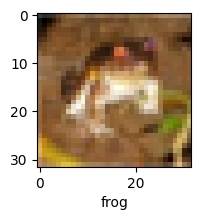

In [11]:
plot_samples(X_train, y_train, 0)

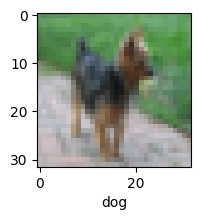

In [12]:
plot_samples(X_train, y_train, 10800)

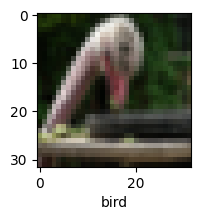

In [13]:
plot_samples(X_train, y_train, 400)

In [14]:
# Normalize (or scaled) value
X_train = X_train / 255
X_test = X_test / 255

## Image classificatio with ANN

In [26]:
ann = models.Sequential([
    layers.Flatten(input_shape=(32,32,3)),
    layers.Dense(3000, activation='relu'),
    layers.Dense(1000, activation='relu'),
    layers.Dense(10, activation='softmax')
])

ann.compile(optimizer='SGD',
            loss='sparse_categorical_crossentropy',
            metrics=['accuracy'])

ann.fit(X_train, y_train, epochs=10)

C:\Users\rosha\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 71s 45ms/step - accuracy: 0.3550 - loss: 1.8152
Epoch 2/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 68s 44ms/step - accuracy: 0.4296 - loss: 1.6217
Epoch 3/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 74s 47ms/step - accuracy: 0.4582 - loss: 1.5385
Epoch 4/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 72s 46ms/step - accuracy: 0.4787 - loss: 1.4797
Epoch 5/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 69s 44ms/step - accuracy: 0.4959 - loss: 1.4287
Epoch 6/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 70s 45ms/step - accuracy: 0.5132 - loss: 1.3864
Epoch 7/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 70s 45ms/step - accuracy: 0.5247 - loss: 1.3490
Epoch 8/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 69s 44ms/step - accuracy: 0.5392 - loss: 1.3118
Epoch 9/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 70s 45ms/step - accuracy: 0.5517 - loss: 1.2797
Epoch 10/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 71s 45ms/step - accuracy: 0.5634 - loss: 1.2502


In [27]:
ann.evaluate(X_test, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.5116 - loss: 1.3809


[1.3808649778366089, 0.5116000175476074]

### Classification Report

In [28]:
from sklearn.metrics import confusion_matrix, classification_report 
import numpy as np
y_pred = ann.predict(X_test)
y_pred_classes = [np.argmax(element) for element in y_pred]

print(classification_report(y_test, y_pred_classes))

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step
              precision    recall  f1-score   support

           0       0.68      0.43      0.53      1000
           1       0.55      0.77      0.64      1000
           2       0.40      0.42      0.41      1000
           3       0.31      0.54      0.39      1000
           4       0.44      0.45      0.45      1000
           5       0.48      0.35      0.40      1000
           6       0.62      0.51      0.56      1000
           7       0.71      0.47      0.57      1000
           8       0.73      0.58      0.64      1000
           9       0.54      0.59      0.56      1000

    accuracy                           0.51     10000
   macro avg       0.54      0.51      0.52     10000
weighted avg       0.54      0.51      0.52     10000



Accuracy is pretty low with ANN . so, we go with 
## Image Classification with CNN

In [32]:
cnn = models.Sequential([
    # cnn
    layers.Conv2D(filters=32, kernel_size=(3,3), activation='relu',  input_shape=(32,32,3)),
    layers.MaxPooling2D((2,2)),

    layers.Conv2D(filters=64, kernel_size=(3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),
    
    # dense network
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])

cnn.compile(optimizer='adam',
            loss='sparse_categorical_crossentropy',
            metrics=['accuracy'])

In [33]:
cnn.fit(X_train, y_train, epochs=10)

Epoch 1/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 21s 11ms/step - accuracy: 0.4831 - loss: 1.4402
Epoch 2/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 19s 12ms/step - accuracy: 0.6228 - loss: 1.0798
Epoch 3/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 19s 12ms/step - accuracy: 0.6716 - loss: 0.9464
Epoch 4/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 19s 12ms/step - accuracy: 0.6999 - loss: 0.8634
Epoch 5/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 19s 12ms/step - accuracy: 0.7238 - loss: 0.7968
Epoch 6/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 19s 12ms/step - accuracy: 0.7415 - loss: 0.7404
Epoch 7/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 19s 12ms/step - accuracy: 0.7593 - loss: 0.6923
Epoch 8/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 19s 12ms/step - accuracy: 0.7749 - loss: 0.6433
Epoch 9/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 19s 12ms/step - accuracy: 0.7862 - loss: 0.6065
Epoch 10/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 19s 12ms/step - accuracy: 0.8014 - loss: 0.5676


In [34]:
cnn.evaluate(X_test, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.6847 - loss: 1.0091


[1.0090901851654053, 0.6847000122070312]

### Prediction

In [36]:
y_test = y_test.reshape(-1,)
y_test[:5]

array([3, 8, 8, 0, 6], dtype=uint8)

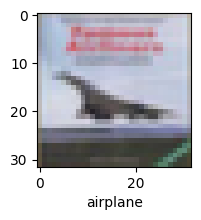

In [47]:
plot_samples(X_test, y_test, 3) # actual value

In [41]:
y_pred = cnn.predict(X_test)
y_pred[:5]

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step


array([[1.10818504e-03, 1.76887843e-04, 1.00939651e-03, 7.92354703e-01,
        2.77876714e-03, 1.83258072e-01, 7.34205171e-03, 5.57023886e-05,
        1.19073922e-02, 8.79199342e-06],
       [1.07074366e-03, 5.74745052e-03, 1.30640707e-08, 4.33273186e-08,
        1.49345492e-09, 2.30620842e-10, 5.73053693e-09, 1.43670936e-10,
        9.93168831e-01, 1.28857491e-05],
       [3.91788371e-02, 2.34319381e-02, 2.98358558e-04, 1.75991416e-04,
        8.40180437e-05, 2.28372155e-05, 1.18799864e-04, 1.05022809e-05,
        9.32810724e-01, 3.86801688e-03],
       [9.89776969e-01, 4.07912489e-03, 6.75812655e-04, 3.21991793e-05,
        7.22911500e-04, 6.24625827e-08, 5.33211751e-05, 1.08208461e-07,
        4.53611603e-03, 1.23296428e-04],
       [1.81815111e-07, 7.04886916e-05, 2.06467346e-03, 2.91677415e-01,
        5.25306880e-01, 3.01038660e-02, 1.50733188e-01, 1.39978374e-05,
        2.38336197e-05, 5.38786435e-06]], dtype=float32)

In [42]:
# from output array we need max value (for max value -> argmax() can be use)

In [45]:
y_classes = [np.argmax(element) for element in y_pred]
y_classes[:5]

[np.int64(3), np.int64(8), np.int64(8), np.int64(0), np.int64(4)]

In [46]:
classes

['airplane',
 'automobile',
 'bird',
 'cat',
 'deer',
 'dog',
 'frog',
 'horse',
 'ship',
 'truck']

In [50]:
classes[y_classes[3]] # predicted values

'airplane'

In [51]:
print(classification_report(y_test, y_classes))

              precision    recall  f1-score   support

           0       0.61      0.82      0.70      1000
           1       0.84      0.77      0.80      1000
           2       0.73      0.43      0.54      1000
           3       0.48      0.54      0.51      1000
           4       0.63      0.63      0.63      1000
           5       0.53      0.64      0.58      1000
           6       0.77      0.77      0.77      1000
           7       0.82      0.67      0.74      1000
           8       0.78      0.82      0.80      1000
           9       0.80      0.76      0.78      1000

    accuracy                           0.68     10000
   macro avg       0.70      0.68      0.68     10000
weighted avg       0.70      0.68      0.68     10000

